# Smart Used Car Selection and Pricing System
## Decision Tree Classifier

### Project Objective
The goal of this project is to build a Decision Tree Classification model that predicts the car model based on its features.

### Dataset
The dataset contains information about used cars, such as:
- Make
- Year
- Kilometers
- Price
- Transmission

### Machine Learning Algorithm
Decision Tree Classifier

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

## 1. Loading the Dataset

In this step, we upload the cleaned dataset and load it using Pandas.

In [35]:
df = pd.read_csv('cars_clean.csv')

df.head()

,id,make,model,year,km,price_egp,transmission,color,city,seller_type,fuel_type
0,7284417,Toyota,Yaris,2009,170000.0,540000,Automatic,Dark blue,Heliopolis,dealer,Petrol
1,7296785,Toyota,Camry,2013,113000.0,1000000,Automatic,White,Nasr city,private,Petrol
2,7293331,Toyota,Corolla,2024,95000.0,1380000,Automatic,Black,Mohandessin,private,Petrol
3,7288941,Toyota,Corolla,2008,210000.0,585000,Automatic,Black,Heliopolis,dealer,Petrol
4,7295928,Toyota,Corolla,2022,126000.0,980000,Automatic,Dark red,Maadi,dealer,Petrol


## 2. Understanding the Dataset

In this step, we explore the dataset to understand its structure, columns, data types, and missing values.

In [36]:
df.shape

(3265, 11)

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3265 entries, 0 to 3264
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            3265 non-null   int64  
 1   make          3265 non-null   object 
 2   model         3265 non-null   object 
 3   year          3265 non-null   int64  
 4   km            3081 non-null   float64
 5   price_egp     3265 non-null   int64  
 6   transmission  3265 non-null   object 
 7   color         3207 non-null   object 
 8   city          3265 non-null   object 
 9   seller_type   3265 non-null   object 
 10  fuel_type     3265 non-null   object 
dtypes: float64(1), int64(3), object(7)
memory usage: 280.7+ KB


In [38]:
df.isnull().sum()

,0
id,0
make,0
model,0
year,0
km,184
price_egp,0
transmission,0
color,58
city,0
seller_type,0


## 4. Handling Rare Classes

Some car models have very few records in the dataset.

To make the classification process more reliable, we keep only car models that have at least 10 records.

In [39]:
model_counts = df['model'].value_counts()

valid_models = model_counts[model_counts >= 10].index

data = df[df['model'].isin(valid_models)].copy()

In [40]:
data.shape

(3047, 11)

In [41]:
data['model'].nunique()

47

## 5. Feature Selection

We select the input features that will be used to predict the car model.

**Features (X):**
- make
- year
- km
- price_egp
- transmission

**Target (y):**
- model

In [42]:
features = ['make', 'year', 'km', 'price_egp', 'transmission']

X = data[features]

y = data['model']

## 6. Splitting the Dataset

We split the dataset into training and testing sets.

- 80% for training.
- 20% for testing.

We use stratify to maintain the same class distribution in both sets.

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [44]:
X_train.shape, X_test.shape

((2437, 5), (610, 5))

## 6. Data Preprocessing

We prepare numerical and categorical features before training the model.

- Numerical features: Missing values are replaced using the median.
- Categorical features: Missing values are replaced using the most frequent value.
- OneHotEncoder converts categorical features into numerical values.

ColumnTransformer is used to apply the appropriate preprocessing to each feature type.

In [45]:
num_cols = ['year', 'km', 'price_egp']

cat_cols = ['make', 'transmission']

In [46]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

In [47]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [48]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

## 7. Building the Decision Tree Classifier

We create a Decision Tree Classifier using Scikit-learn.

The model learns decision rules from the training data to predict the car model.

In [49]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

## 8. Model Training

We train the Decision Tree Classifier using the training dataset.

In [50]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['year', 'km', 'price_egp']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['make', 'transmission'])])),
                ('classifier', DecisionTreeClassifier(random_state=42))])

## 9. Making Predictions

After training, we use the model to predict car models for the testing dataset.

In [51]:
y_pred = model.predict(X_test)

In [52]:
y_pred[:10]

array(['Juke', 'Sportage', 'Sunny', 'Qashqai', 'Cerato', 'Excel',
       'Carnival', 'Cerato', 'Sunny', 'Sentra'], dtype=object)

## 10. Model Evaluation

We evaluate the performance of the Decision Tree Classifier using:

- Accuracy: Measures the percentage of correct predictions.
- Precision: Measures how many predicted samples are correct.
- Recall: Measures how many actual samples are correctly identified.
- F1-score: Combines Precision and Recall.

In [53]:
accuracy = accuracy_score(y_test, y_pred)

accuracy

0.5721311475409836

In [54]:
classification_report(y_test, y_pred, zero_division=0)

'              precision    recall  f1-score   support\n\n      Accent       0.55      0.57      0.56        21\n   Accent Rb       0.32      0.44      0.37        16\n        Atos       0.20      0.33      0.25         3\n      Avante       0.50      0.38      0.43         8\n      Carens       0.38      0.33      0.36        15\n    Carnival       0.50      0.20      0.29         5\n      Cerato       0.30      0.30      0.30        33\n     Corolla       0.83      0.92      0.87        48\n       Creta       0.00      0.00      0.00         3\n     Elantra       0.19      0.23      0.21        22\n  Elantra Ad       0.44      0.44      0.44         9\n Elantra Cn7       0.44      0.44      0.44         9\n  Elantra Hd       0.30      0.30      0.30        10\n  Elantra Md       0.56      0.62      0.59         8\n       Excel       0.67      0.60      0.63        10\n    Fortuner       1.00      0.83      0.91         6\n        Getz       0.00      0.00      0.00         5\nGrand C

## 11. Hyperparameter Tuning

We use GridSearchCV to find the best hyperparameters for the Decision Tree Classifier.

This process tests different parameter combinations using cross-validation.

In [55]:
param_grid = {
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

In [56]:
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median'))]),
                                                                         ['year',
                                                                          'km',
                                                                          'price_egp']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('encoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['make',
                                                                          'transmission'])])),
                                       ('classifier',
                                        DecisionTreeClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__max_depth': [5, 10, 15, None],
                         'classifier__min_samples_leaf': [1, 2, 4],
                         'classifier__min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [57]:
grid_search.best_params_

{'classifier__max_depth': 10,
 'classifier__min_samples_leaf': 1,
 'classifier__min_samples_split': 2}

In [58]:
grid_search.best_score_

np.float64(0.6347990372639446)

## 12. Evaluating the Best Model

We use the best estimator selected by GridSearchCV to make predictions on the testing dataset.

Then, we evaluate its performance using Accuracy and Classification Report.

In [59]:
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test)

In [60]:
accuracy_score(y_test, y_pred_best)

0.6114754098360655

In [61]:
classification_report(y_test, y_pred_best, zero_division=0)

'              precision    recall  f1-score   support\n\n      Accent       0.56      0.71      0.62        21\n   Accent Rb       0.50      0.50      0.50        16\n        Atos       0.00      0.00      0.00         3\n      Avante       0.25      0.12      0.17         8\n      Carens       0.27      0.27      0.27        15\n    Carnival       0.33      0.20      0.25         5\n      Cerato       0.38      0.39      0.39        33\n     Corolla       0.92      0.92      0.92        48\n       Creta       0.00      0.00      0.00         3\n     Elantra       0.25      0.14      0.18        22\n  Elantra Ad       0.30      0.33      0.32         9\n Elantra Cn7       0.56      1.00      0.72         9\n  Elantra Hd       0.39      0.70      0.50        10\n  Elantra Md       0.44      0.88      0.58         8\n       Excel       0.71      0.50      0.59        10\n    Fortuner       1.00      0.83      0.91         6\n        Getz       0.00      0.00      0.00         5\nGrand C

## 13. Decision Tree Visualization

We visualize the trained Decision Tree to understand how the model makes its classification decisions.

We display the first three levels of the tree for better readability.

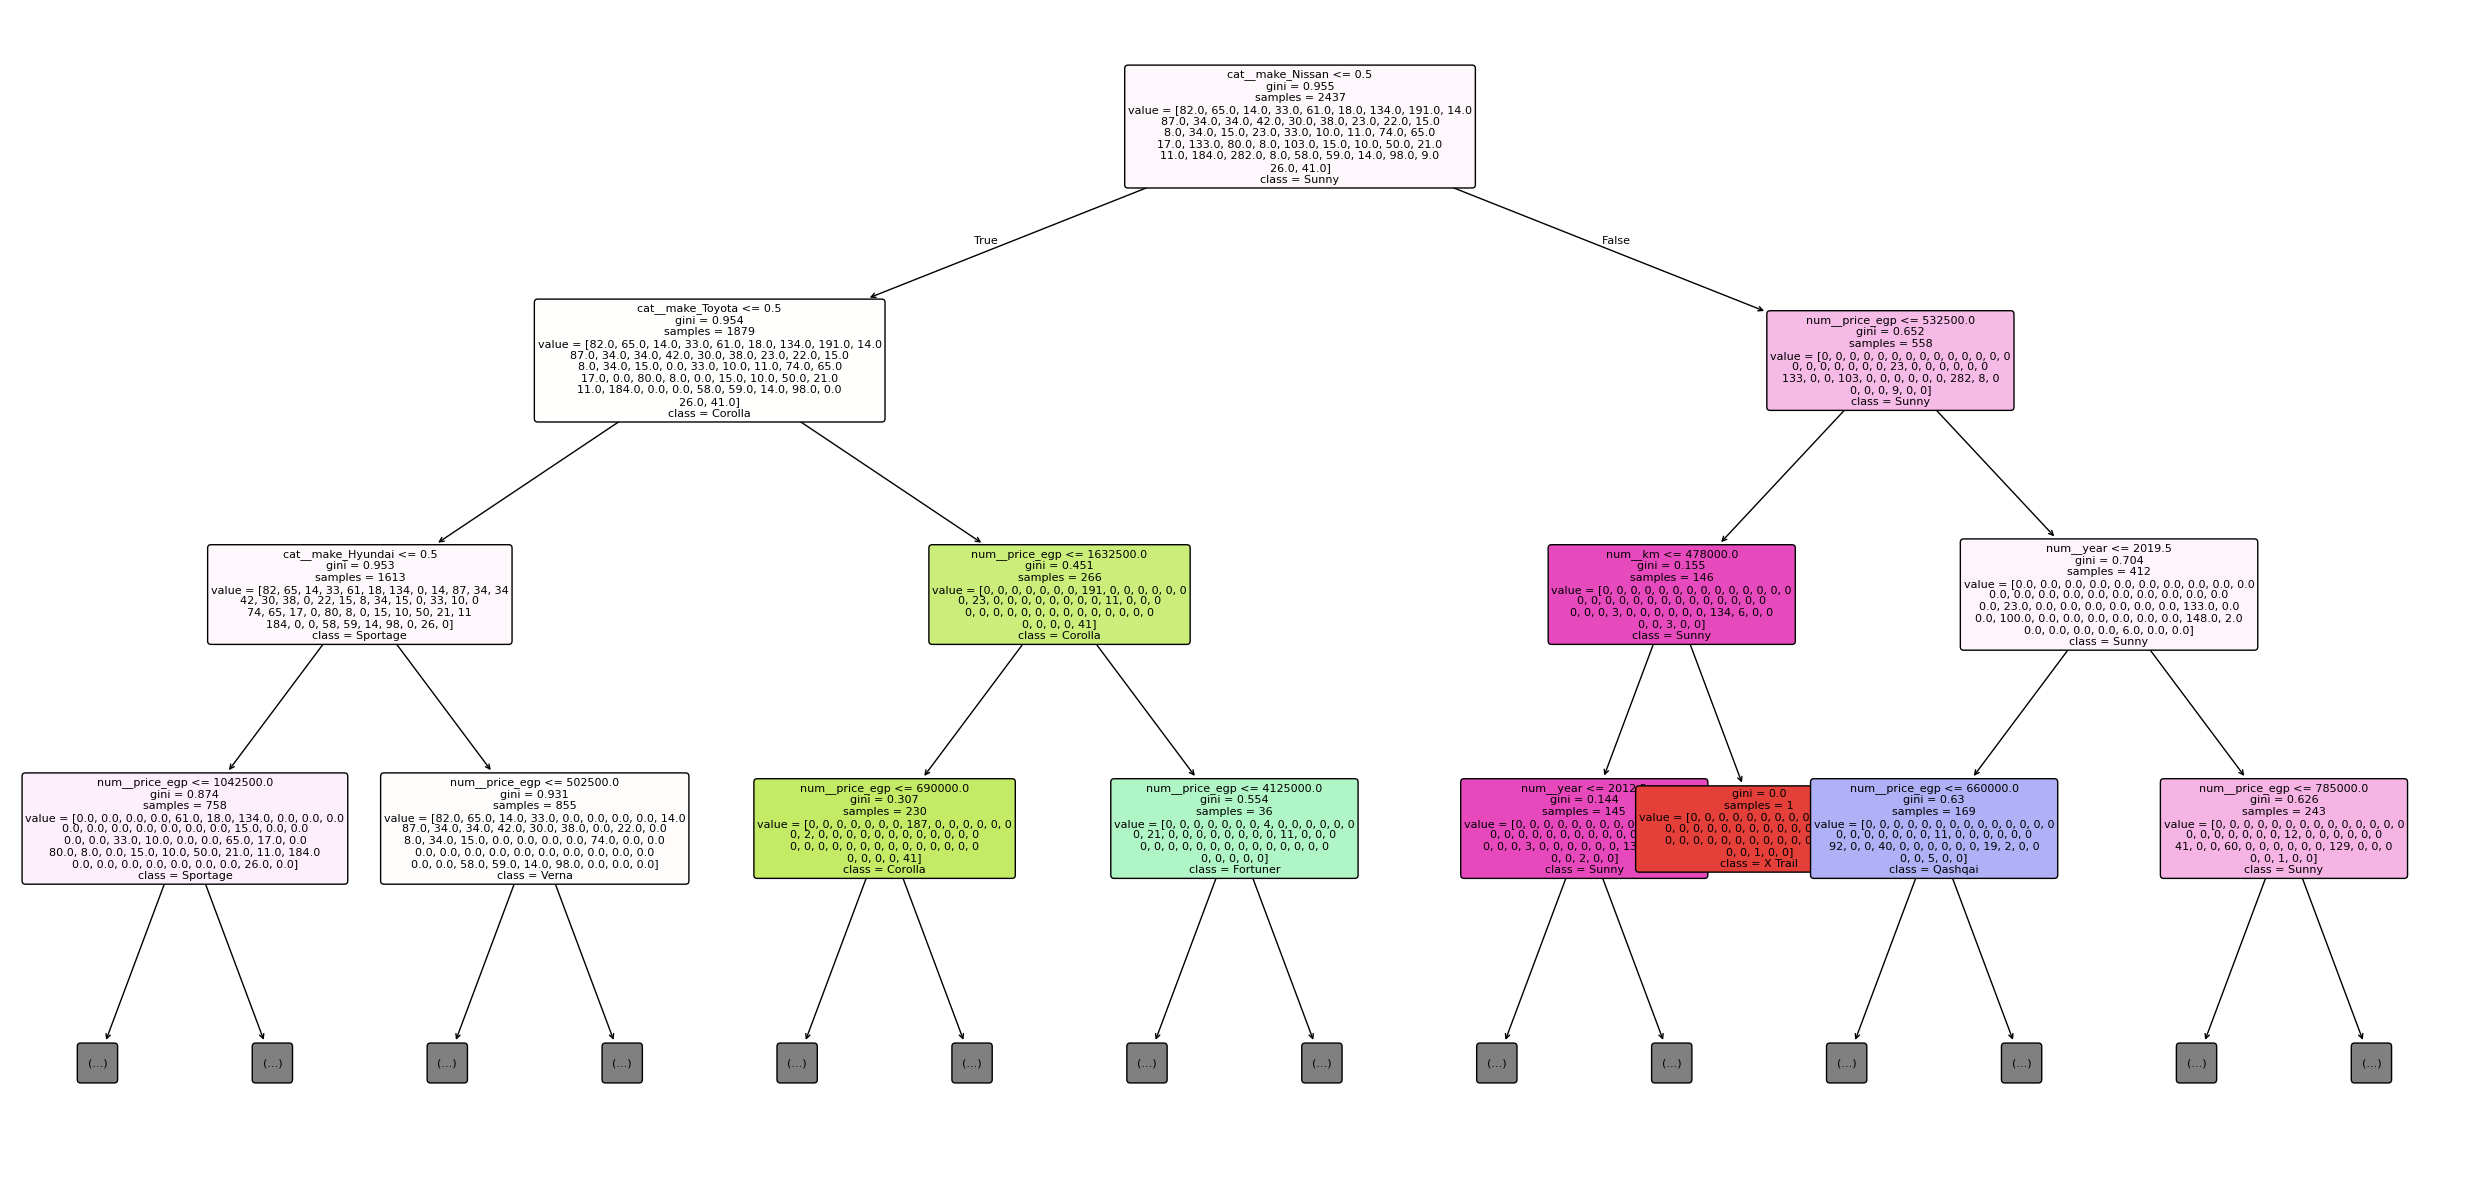

In [62]:
tree_model = best_model.named_steps['classifier']

feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

plt.figure(figsize=(25, 12))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=[str(c) for c in tree_model.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.tight_layout()
plt.show()

## 14. Conclusion

In this project, we developed a Decision Tree Classifier to predict used car models based on their features.

We performed data exploration, preprocessing, feature selection, and train-test splitting.

We trained the model and evaluated its performance using Accuracy, Precision, Recall, and F1-score.

We also used GridSearchCV to optimize the model's hyperparameters and improve its performance.